In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [18]:
dataframe = pd.read_csv ("Diabetes Dataset.csv")

In [19]:
dataframe.head()

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
2,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,634,34224,F,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0,N
4,721,34225,F,50,2.0,50,4.0,3.6,1.3,0.9,2.1,0.6,24.0,N


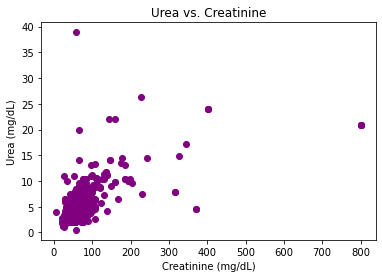

In [20]:
# Create a scatter plot of Urea vs. Creatinine
plt.scatter(dataframe["Cr"], dataframe["Urea"],c = 'purple')
plt.xlabel("Creatinine (mg/dL)")
plt.ylabel("Urea (mg/dL)")
plt.title("Urea vs. Creatinine")
plt.show()

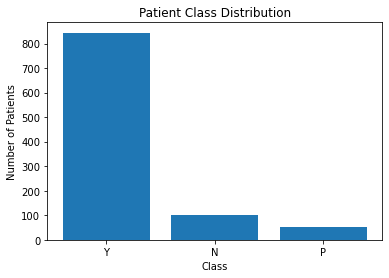

In [23]:
# Count the number of patients in each class
class_counts = dataframe["CLASS"].value_counts()

plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Patients")
plt.title("Patient Class Distribution")
plt.show()

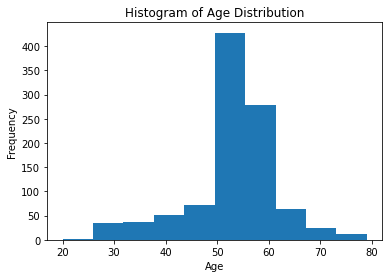

In [6]:
# Create a histogram of Age distribution
dataframe["AGE"].plot(kind="hist")

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Histogram of Age Distribution")
plt.show()

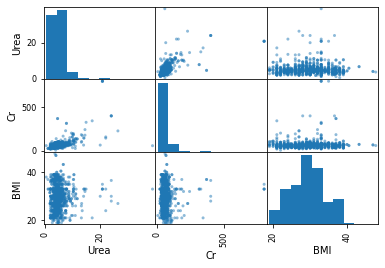

In [7]:
# Create a scatter plot matrix of Urea, Creatinine, and BMI levels
from pandas.plotting import scatter_matrix

scatter_matrix(dataframe[["Urea", "Cr", "BMI"]])
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

In [9]:
dataframe = dataframe[dataframe['CLASS'] != 'P']
dataframe.drop('No_Pation',  axis=1, inplace = True)
dataframe.drop('Gender',  axis=1, inplace = True)

In [10]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='most_frequent')
dataframe = pd.DataFrame(imputer.fit_transform(dataframe), columns=dataframe.columns)


In [11]:
# Split the dataset into training and test sets
X = dataframe.drop('CLASS', axis=1)
y = dataframe['CLASS']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
X.head()

,ID,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
0,502,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0
1,420,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0
2,680,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0
3,634,45,2.3,24,4.0,2.9,1.0,1.0,1.5,0.4,21.0
4,721,50,2.0,50,4.0,3.6,1.3,0.9,2.1,0.6,24.0


In [12]:
# Scale the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

LogisticRegression()

In [14]:
y_pred = logreg.predict(X_test)


In [15]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 29   2]
 [  9 245]]
